# ❤️ Heart Disease Prediction using Logistic Regression

Predict whether a patient has heart disease (`target = 1`) or a healthy heart (`target = 0`) from 13 clinical features.

**Dataset:** [Heart Disease Dataset – Kaggle](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset) (1,025 patient records, 14 columns)

**Steps:** load data → check quality → explore → train/test split → train logistic regression → evaluate → predict for a new patient → compare smaller feature sets

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# In Google Colab, upload heart.csv and use '/content/heart.csv'
data = pd.read_csv('heart.csv')
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [2]:
print('Rows, columns:', data.shape)
data.columns.tolist()

Rows, columns: (1025, 14)


['age',
 'sex',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalach',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal',
 'target']

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (0–3) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | Resting ECG results (0–2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise |
| slope | Slope of the peak exercise ST segment |
| ca | Number of major vessels (0–4) |
| thal | Thalassemia type |
| **target** | **1 = heart disease, 0 = healthy heart** |

## 2. Data quality checks

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [4]:
# Missing values per column
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [5]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


## 3. Explore the target variable
A balanced target (similar number of 0s and 1s) means accuracy is a fair metric and the model will not simply favour one class.

target
1    526
0    499
Name: count, dtype: int64


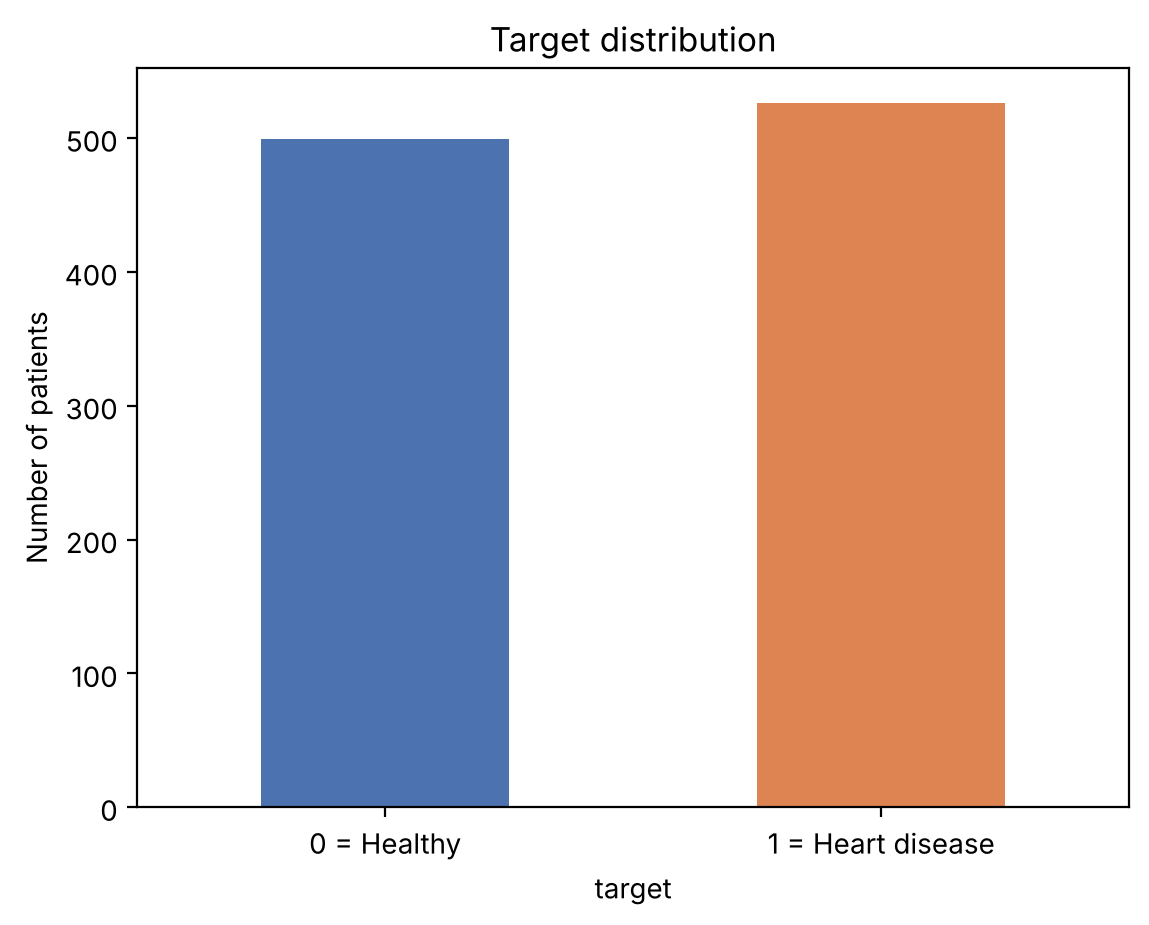

In [6]:
counts = data['target'].value_counts()
print(counts)

counts.sort_index().plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.xticks([0, 1], ['0 = Healthy', '1 = Heart disease'], rotation=0)
plt.ylabel('Number of patients')
plt.title('Target distribution')
plt.show()

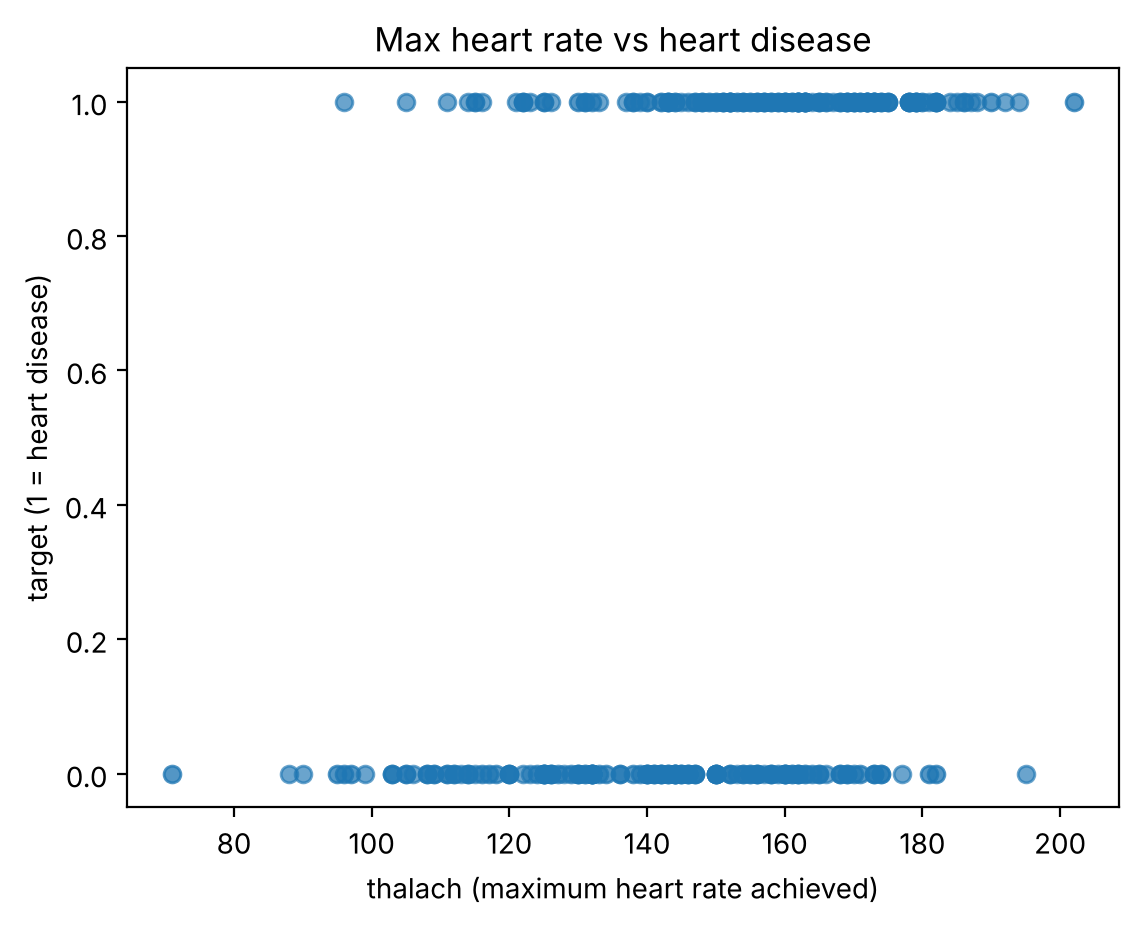

In [7]:
plt.scatter(data['thalach'], data['target'], alpha=0.3)
plt.xlabel('thalach (maximum heart rate achieved)')
plt.ylabel('target (1 = heart disease)')
plt.title('Max heart rate vs heart disease')
plt.show()

## 4. Split into training and test data
70% of rows train the model and 30% test it. `stratify=y` keeps the same share of 0s and 1s in both sets.

In [8]:
x = data.drop(columns='target')
y = data['target']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, stratify=y, random_state=5)

print(x.shape, x_train.shape, x_test.shape)

(1025, 13) (717, 13) (308, 13)


## 5. Train the logistic regression model
The features are on very different scales (e.g. cholesterol ≈ 250 vs sex = 0/1), so they are standardised first with `StandardScaler`. This lets the model train properly (converge) and treats every feature fairly.

In [9]:
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 6. Evaluate the model

In [10]:
train_accuracy = accuracy_score(y_train, model.predict(x_train))
y_pred = model.predict(x_test)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'Accuracy on training data: {train_accuracy:.2%}')
print(f'Accuracy on test data:     {test_accuracy:.2%}')

Accuracy on training data: 84.10%
Accuracy on test data:     85.39%


[[119  31]
 [ 14 144]]


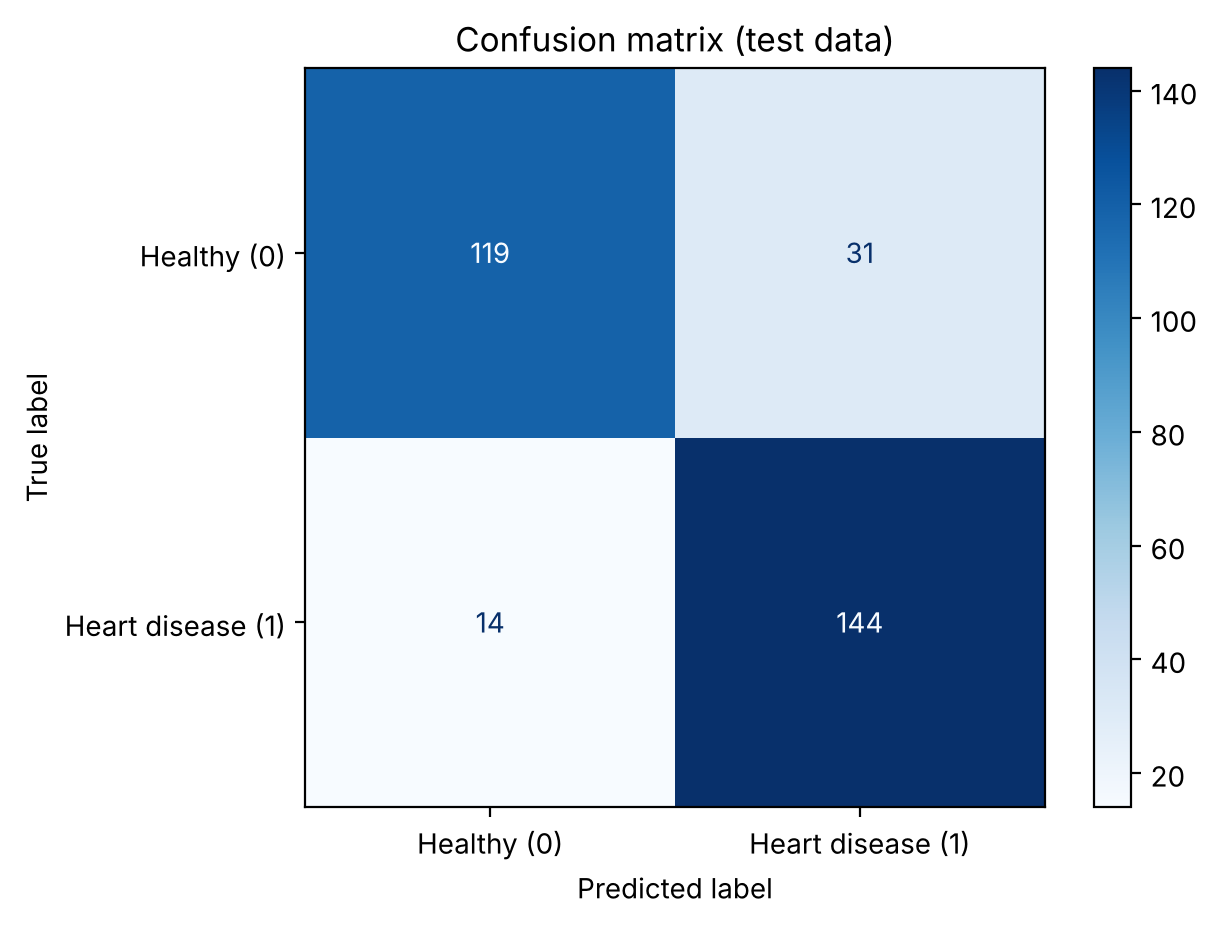

In [11]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=['Healthy (0)', 'Heart disease (1)']).plot(cmap='Blues')
plt.title('Confusion matrix (test data)')
plt.show()

- **Precision:** of the patients predicted to have heart disease, how many really do.
- **Recall:** of the patients who really have heart disease, how many the model catches. In a medical setting this matters most, because a missed case is costly.
- **F1-score:** the balance of precision and recall.
- **Support:** number of patients in each class in the test set.

In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.79      0.84       150
           1       0.82      0.91      0.86       158

    accuracy                           0.85       308
   macro avg       0.86      0.85      0.85       308
weighted avg       0.86      0.85      0.85       308



## 7. Predictive system
Enter one patient's 13 values (in the same column order as the dataset) to get a prediction.

In [13]:
input_data = (51, 1, 0, 140, 298, 0, 1, 122, 1, 4.2, 1, 3, 3)

patient = pd.DataFrame([input_data], columns=x.columns)
prediction = model.predict(patient)[0]

if prediction == 0:
    print('The person does not have heart disease')
else:
    print('The person has heart disease')

The person does not have heart disease


## 8. Do fewer features work as well?
Train the same model on three smaller feature sets and compare test accuracy with the full 13-feature model.

In [14]:
feature_sets = {
    'All 13 features': list(x.columns),
    'Set 1: age, cp, trestbps, chol, fbs': ['age', 'cp', 'trestbps', 'chol', 'fbs'],
    'Set 2: restecg, thalach, oldpeak, trestbps, chol': ['restecg', 'thalach', 'oldpeak', 'trestbps', 'chol'],
    'Set 3: sex, restecg, ca, thalach, trestbps': ['sex', 'restecg', 'ca', 'thalach', 'trestbps'],
}

results = []
for name, cols in feature_sets.items():
    xs_train, xs_test, ys_train, ys_test = train_test_split(
        x[cols], y, test_size=0.3, stratify=y, random_state=5)
    m = make_pipeline(StandardScaler(), LogisticRegression()).fit(xs_train, ys_train)
    results.append({
        'Feature set': name,
        'Train accuracy': accuracy_score(ys_train, m.predict(xs_train)),
        'Test accuracy': accuracy_score(ys_test, m.predict(xs_test)),
    })

results = pd.DataFrame(results)
results[['Train accuracy', 'Test accuracy']] = (results[['Train accuracy', 'Test accuracy']] * 100).round(2)
results

,Feature set,Train accuracy,Test accuracy
0,All 13 features,84.10,85.39
1,"Set 1: age, cp, trestbps, chol, fbs",74.48,73.38
2,"Set 2: restecg, thalach, oldpeak, trestbps, chol",71.69,75.97
3,"Set 3: sex, restecg, ca, thalach, trestbps",76.99,79.22


## 9. Conclusion

- The logistic regression model using **all 13 features** reaches **85.39% test accuracy** (84.10% on training data). The two are close, so the model is not overfitting.
- On the test data it correctly identifies **144 of 158** patients with heart disease (**recall 0.91**), which matters most in a medical setting.
- Using only 5 features lowers test accuracy to **73–79%**, so the **full feature set performs best**.

**Limitation:** this Kaggle file contains many repeated rows (only 302 of the 1,025 rows are unique), so the same patient can appear in both training and test data. The accuracy may therefore be optimistic; a next step would be to remove duplicates and use cross-validation.